## 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns and format decimals in tables
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Chart style
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.titleweight"] = "bold"

## 2. Mount Google Drive

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 3. Import data

pandas reads `"n/a"` and `"NULL"` as missing values (NaN) by default.
`Customers.csv` is not UTF-8, so it is read with `encoding="latin-1"`.

In [7]:
sales = pd.read_csv("/content/drive/MyDrive/DEPI final project team 1/Datasets/Sales (1).csv")
customers = pd.read_csv("/content/drive/MyDrive/DEPI final project team 1/Datasets/Customers.csv", encoding="latin-1")
products = pd.read_csv("/content/drive/MyDrive/DEPI final project team 1/Datasets/Products.csv")

In [8]:
sales.head()

,order_number,product_key,customer_key,order_date,shipping_date,due_date,sales_amount,quantity,price
0,SO54496,282,5400,3/16/2025,3/23/2025,3/28/2025,25,1,25
1,SO54496,289,5400,3/16/2025,3/23/2025,3/28/2025,5,1,5
2,SO54496,259,5400,3/16/2025,3/23/2025,3/28/2025,2,1,2
3,SO54497,174,9281,3/16/2025,3/23/2025,3/28/2025,22,1,22
4,SO54497,280,9281,3/16/2025,3/23/2025,3/28/2025,9,1,9


In [9]:
customers.head()

,customer_key,customer_id,customer_number,first_name,last_name,country,marital_status,gender,birthdate
0,1,11000,AW00011000,Jon,Yang,Australia,Married,Male,10/6/1991
1,2,11001,AW00011001,Eugene,Huang,Australia,Single,Male,5/10/1996
2,3,11002,AW00011002,Ruben,Torres,Australia,Married,Male,2/9/1991
3,4,11003,AW00011003,Christy,Zhu,Australia,Single,Female,8/14/1993
4,5,11004,AW00011004,Elizabeth,Johnson,Australia,Single,Female,8/5/1999


In [10]:
products.head()

,product-key,product_id,product_number,product_name,category_id,category,subcategory,maintenance,cost,product_line
0,1,210,FR-R92B-58,HL Road Frame - Black- 58,CO_RF,Components,Road Frames,Yes,0,Road
1,2,211,FR-R92R-58,HL Road Frame - Red- 58,CO_RF,Components,Road Frames,Yes,0,Road
2,3,348,BK-M82B-38,Mountain-100 Black- 38,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain
3,4,349,BK-M82B-42,Mountain-100 Black- 42,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain
4,5,350,BK-M82B-44,Mountain-100 Black- 44,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain


## 4. Data exploration

### 4.1 Shape and data types

In [11]:
print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Sales: (60398, 9)
Customers: (18484, 9)
Products: (295, 10)


In [12]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   order_number   60398 non-null  object
 1   product_key    60398 non-null  int64 
 2   customer_key   60398 non-null  int64 
 3   order_date     60379 non-null  object
 4   shipping_date  60398 non-null  object
 5   due_date       60398 non-null  object
 6   sales_amount   60398 non-null  int64 
 7   quantity       60398 non-null  int64 
 8   price          60398 non-null  int64 
dtypes: int64(5), object(4)
memory usage: 4.1+ MB


In [13]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18484 entries, 0 to 18483
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   customer_key     18484 non-null  int64 
 1   customer_id      18484 non-null  int64 
 2   customer_number  18484 non-null  object
 3   first_name       18484 non-null  object
 4   last_name        18484 non-null  object
 5   country          18147 non-null  object
 6   marital_status   18484 non-null  object
 7   gender           18469 non-null  object
 8   birthdate        18467 non-null  object
dtypes: int64(2), object(7)
memory usage: 1.3+ MB


In [14]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   product-key     295 non-null    int64 
 1   product_id      295 non-null    int64 
 2   product_number  295 non-null    object
 3   product_name    295 non-null    object
 4   category_id     295 non-null    object
 5   category        288 non-null    object
 6   subcategory     288 non-null    object
 7   maintenance     288 non-null    object
 8   cost            295 non-null    int64 
 9   product_line    278 non-null    object
dtypes: int64(3), object(7)
memory usage: 23.2+ KB


- Date columns (`order_date`, `shipping_date`, `due_date`, `birthdate`) are stored as text.
- The products key is called `product-key`, while the sales table uses `product_key`.

### 4.2 Summary statistics

In [15]:
sales[["sales_amount", "quantity", "price"]].describe()

,sales_amount,quantity,price
count,"60,398.00","60,398.00","60,398.00"
mean,486.05,1.00,486.04
std,928.45,0.04,928.45
min,2.00,1.00,2.00
25%,8.00,1.00,8.00
50%,30.00,1.00,30.00
75%,540.00,1.00,540.00
max,"3,578.00",10.00,"3,578.00"


In [16]:
products["cost"].describe()

,cost
count,295.00
mean,431.07
std,533.62
min,0.00
25%,33.50
50%,200.00
75%,602.00
max,"2,171.00"


### 4.3 Values in text columns

In [17]:
display(customers["country"].value_counts(dropna=False))
display(customers["gender"].value_counts(dropna=False))
display(customers["marital_status"].value_counts(dropna=False))

,count
country,
United States,7482
Australia,3591
United Kingdom,1913
France,1810
Germany,1780
Canada,1571
NaN,337


,count
gender,
Male,9341
Female,9128
NaN,15


,count
marital_status,
Married,10011
Single,8473


In [18]:
display(products["category"].value_counts(dropna=False))
display(products["maintenance"].value_counts(dropna=False))
display(products["product_line"].value_counts(dropna=False))

,count
category,
Components,127
Bikes,97
Clothing,35
Accessories,29
NaN,7


,count
maintenance,
Yes,226
No,62
NaN,7


,count
product_line,
Road,100
Mountain,91
Touring,52
Other Sales,35
NaN,17


### 4.4 Missing values

In [19]:
sales.isna().sum()

,0
order_number,0
product_key,0
customer_key,0
order_date,19
shipping_date,0
due_date,0
sales_amount,0
quantity,0
price,0


In [20]:
customers.isna().sum()

,0
customer_key,0
customer_id,0
customer_number,0
first_name,0
last_name,0
country,337
marital_status,0
gender,15
birthdate,17


In [21]:
products.isna().sum()

,0
product-key,0
product_id,0
product_number,0
product_name,0
category_id,0
category,7
subcategory,7
maintenance,7
cost,0
product_line,17


### 4.5 Data quality checks

In [22]:
quality_checks = pd.Series({
    "Duplicate rows in sales": sales.duplicated().sum(),
    "Duplicate rows in customers": customers.duplicated().sum(),
    "Duplicate rows in products": products.duplicated().sum(),
    "Sales with unknown product": (~sales["product_key"].isin(products["product-key"])).sum(),
    "Sales with unknown customer": (~sales["customer_key"].isin(customers["customer_key"])).sum(),
    "sales_amount not equal to quantity x price": (sales["sales_amount"] != sales["quantity"] * sales["price"]).sum(),
    "Zero or negative sales_amount": (sales["sales_amount"] <= 0).sum(),
    "Products with cost = 0": (products["cost"] == 0).sum(),
    "Customer names with broken characters": customers["first_name"].str.contains(r"[^A-Za-z .'-]").sum(),
})
quality_checks

,0
Duplicate rows in sales,0
Duplicate rows in customers,0
Duplicate rows in products,0
Sales with unknown product,0
Sales with unknown customer,0
sales_amount not equal to quantity x price,0
Zero or negative sales_amount,0
Products with cost = 0,2
Customer names with broken characters,38


In [23]:
# Products with missing category, subcategory and maintenance
products[products["category"].isna()]

,product-key,product_id,product_number,product_name,category_id,category,subcategory,maintenance,cost,product_line
251,252,542,PD-M282,LL Mountain Pedal,CO_PE,NaN,NaN,NaN,18,Mountain
252,253,543,PD-M340,ML Mountain Pedal,CO_PE,NaN,NaN,NaN,28,Mountain
253,254,544,PD-M562,HL Mountain Pedal,CO_PE,NaN,NaN,NaN,36,Mountain
254,255,545,PD-R347,LL Road Pedal,CO_PE,NaN,NaN,NaN,18,Road
255,256,546,PD-R563,ML Road Pedal,CO_PE,NaN,NaN,NaN,28,Road
256,257,547,PD-R853,HL Road Pedal,CO_PE,NaN,NaN,NaN,36,Road
257,258,548,PD-T852,Touring Pedal,CO_PE,NaN,NaN,NaN,36,Touring


In [24]:
# Products with missing product line
products[products["product_line"].isna()]

,product-key,product_id,product_number,product_name,category_id,category,subcategory,maintenance,cost,product_line
50,51,391,FK-1639,LL Fork,CO_FO,Components,Forks,Yes,66,NaN
51,52,392,FK-5136,ML Fork,CO_FO,Components,Forks,Yes,78,NaN
52,53,393,FK-9939,HL Fork,CO_FO,Components,Forks,Yes,102,NaN
73,74,394,HS-0296,LL Headset,CO_HS,Components,Headsets,No,15,NaN
74,75,395,HS-2451,ML Headset,CO_HS,Components,Headsets,No,45,NaN
75,76,396,HS-3479,HL Headset,CO_HS,Components,Headsets,No,55,NaN
100,101,601,BB-7421,LL Bottom Bracket,CO_BB,Components,Bottom Brackets,Yes,24,NaN
101,102,602,BB-8107,ML Bottom Bracket,CO_BB,Components,Bottom Brackets,Yes,45,NaN
102,103,603,BB-9108,HL Bottom Bracket,CO_BB,Components,Bottom Brackets,Yes,54,NaN
166,167,559,CH-0234,Chain,CO_CH,Components,Chains,Yes,9,NaN


In [25]:
# Products with cost = 0
products[products["cost"] == 0]

,product-key,product_id,product_number,product_name,category_id,category,subcategory,maintenance,cost,product_line
0,1,210,FR-R92B-58,HL Road Frame - Black- 58,CO_RF,Components,Road Frames,Yes,0,Road
1,2,211,FR-R92R-58,HL Road Frame - Red- 58,CO_RF,Components,Road Frames,Yes,0,Road


**Exploration summary**

| Table | Issue | Rows |
|---|---|---|
| Customers | Missing `country` | 337 |
| Customers | Missing `gender` | 15 |
| Customers | Missing `birthdate` | 17 |
| Customers | Broken characters in names (encoding) | 38 |
| Products | Missing `category`, `subcategory`, `maintenance` (all `CO_PE`) | 7 |
| Products | Missing `product_line` | 17 |
| Products | `cost` = 0 | 2 |
| Products | Key column named `product-key` | – |
| Sales | Missing `order_date` | 19 |
| All | Dates stored as text | – |

## 5. Data cleaning

### 5.1 Products

In [26]:
# Rename the key column to match the sales table
products = products.rename(columns={"product-key": "product_key"})

# The 7 CO_PE products are pedals: "CO" means Components in category_id, and all their names end in "Pedal"
products["category"] = products["category"].fillna("Components")
products["subcategory"] = products["subcategory"].fillna("Pedals")

# Maintenance cannot be known from the data
products["maintenance"] = products["maintenance"].fillna("Unknown")

# Missing product line
products["product_line"] = products["product_line"].fillna("Other Sales")

# Cost = 0 is not a real cost: the size-58 "HL Road Frame" items cost 0, while all other sizes cost 869
# Replace 0 with NaN, then fill it with the median cost of the same model ("HL Road Frame")
products["cost"] = products["cost"].replace(0, np.nan)
products["model"] = products["product_name"].str.split(" - ").str[0]
products["cost"] = products["cost"].fillna(products.groupby("model")["cost"].transform("median"))
products = products.drop(columns="model")

products.isna().sum()

,0
product_key,0
product_id,0
product_number,0
product_name,0
category_id,0
category,0
subcategory,0
maintenance,0
cost,0
product_line,0


### 5.2 Sales

In [27]:
# Convert the date columns from text to dates
sales["order_date"] = pd.to_datetime(sales["order_date"], format="%m/%d/%Y")
sales["shipping_date"] = pd.to_datetime(sales["shipping_date"], format="%m/%d/%Y")
sales["due_date"] = pd.to_datetime(sales["due_date"], format="%m/%d/%Y")

In [28]:
# Days between order and shipping: almost always exactly 7
(sales["shipping_date"] - sales["order_date"]).dt.days.value_counts()

,count
7.00,60366
6.00,11
8.00,2


In [29]:
# Fill missing order dates:
# 1) with the date of another line from the same order
sales["order_date"] = sales["order_date"].fillna(sales.groupby("order_number")["order_date"].transform("first"))

# 2) the rest with shipping date minus 7 days
sales["order_date"] = sales["order_date"].fillna(sales["shipping_date"] - pd.Timedelta(days=7))

# Shipping duration in days
sales["shipping_duration"] = (sales["shipping_date"] - sales["order_date"]).dt.days

sales.isna().sum()

,0
order_number,0
product_key,0
customer_key,0
order_date,0
shipping_date,0
due_date,0
sales_amount,0
quantity,0
price,0
shipping_duration,0


### 5.3 Customers

In [30]:
# Missing country and gender become "Unknown"
customers["country"] = customers["country"].fillna("Unknown")
customers["gender"] = customers["gender"].fillna("Unknown")

# Convert birthdate to a date (missing values stay empty)
customers["birthdate"] = pd.to_datetime(customers["birthdate"], format="%m/%d/%Y")

# Age at the last order date in the data
last_order_date = sales["order_date"].max()
customers["age"] = np.floor((last_order_date - customers["birthdate"]).dt.days / 365.25)

# Age groups (customers without a birthdate get "Unknown")
customers["age_group"] = pd.cut(customers["age"],
                                bins=[0, 29, 39, 49, 59, 120],
                                labels=["Under 30", "30-39", "40-49", "50-59", "60+"])
customers["age_group"] = customers["age_group"].cat.add_categories("Unknown").fillna("Unknown")

customers.isna().sum()

,0
customer_key,0
customer_id,0
customer_number,0
first_name,0
last_name,0
country,0
marital_status,0
gender,0
birthdate,17
age,17


The 17 missing birthdates (and their `age`) are expected; those customers are grouped as "Unknown" in `age_group`.
Names with broken characters are left as they are, since names are not used in the analysis.

## 6. Analysis table

In [31]:
# Join sales with products and customers
df = sales.merge(products, on="product_key", how="left")
df = df.merge(customers, on="customer_key", how="left")

# Cost, profit and date columns
df["cost_amount"] = df["cost"] * df["quantity"]
df["profit"] = df["sales_amount"] - df["cost_amount"]
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.to_period("M")

df.shape

(60398, 33)

## 7. Exploratory data analysis (EDA)

### 7.1 Headline KPIs

In [32]:
total_revenue = df["sales_amount"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_number"].nunique()
total_customers = df["customer_key"].nunique()

kpis = pd.Series({
    "Total revenue": total_revenue,
    "Total profit": total_profit,
    "Profit margin (%)": np.round(total_profit / total_revenue * 100, 1),
    "Orders": total_orders,
    "Customers": total_customers,
    "Units sold": df["quantity"].sum(),
    "Average order value": total_revenue / total_orders,
    "Orders per customer": total_orders / total_customers,
})
kpis

,0
Total revenue,"29,356,250.00"
Total profit,"11,685,757.00"
Profit margin (%),39.80
Orders,"27,659.00"
Customers,"18,484.00"
Units sold,"60,423.00"
Average order value,"1,061.36"
Orders per customer,1.50


### 7.2 Sales over time

The first month (Dec 2022) and last month (Jan 2026) only have a few days of data, so they are left out of the monthly charts.

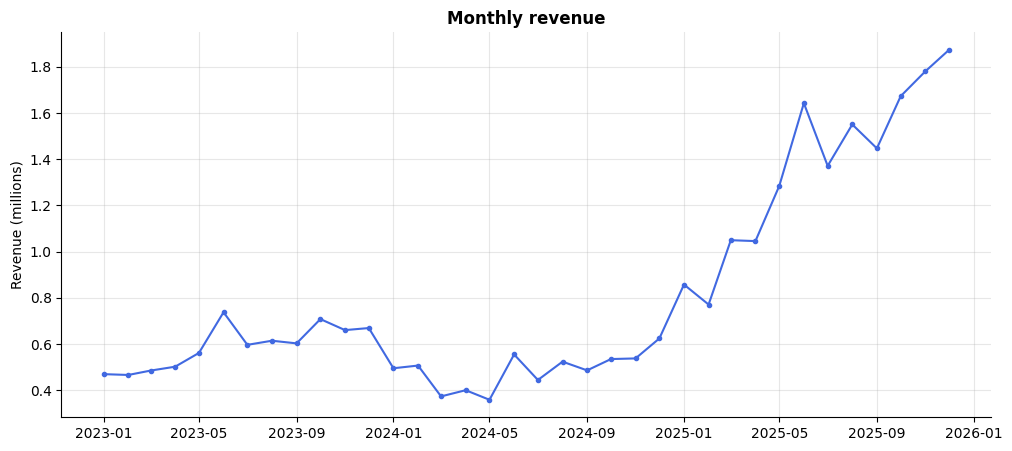

In [33]:
monthly = df.groupby("order_month").agg(revenue=("sales_amount", "sum"),
                                        orders=("order_number", "nunique"))
monthly = monthly.iloc[1:-1]   # drop the incomplete first and last months
months = monthly.index.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(months, monthly["revenue"] / 1e6, marker="o", markersize=3, color="royalblue")
plt.title("Monthly revenue")
plt.ylabel("Revenue (millions)")
plt.show()

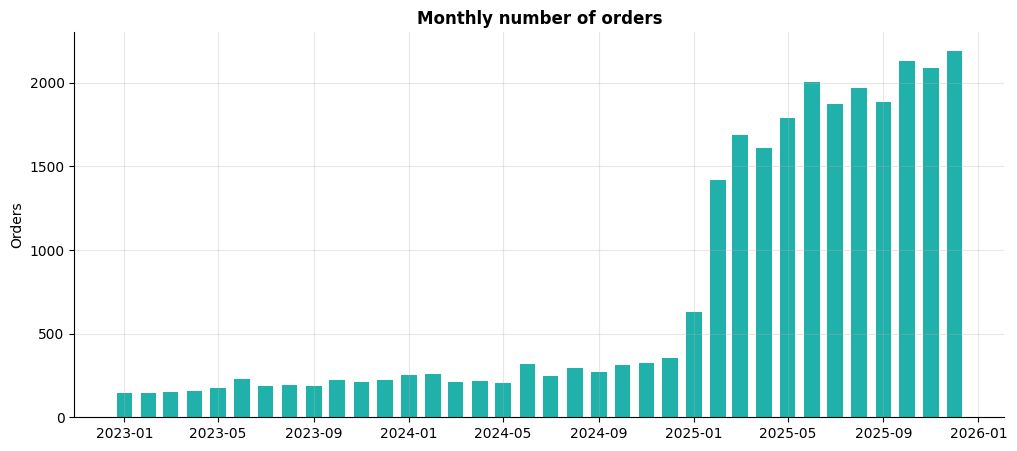

In [34]:
plt.figure(figsize=(12, 5))
plt.bar(months, monthly["orders"], width=20, color="lightseagreen")
plt.title("Monthly number of orders")
plt.ylabel("Orders")
plt.show()

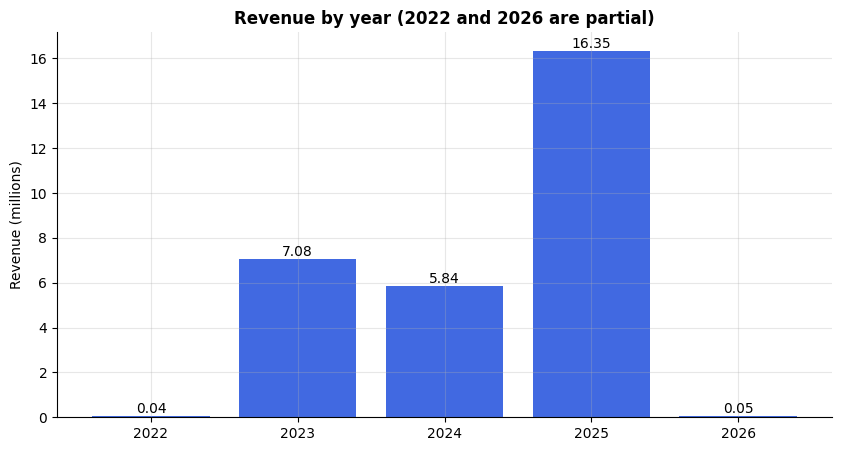

In [35]:
yearly = df.groupby("order_year")["sales_amount"].sum() / 1e6

bars = plt.bar(yearly.index.astype(str), yearly.values, color="royalblue")
plt.bar_label(bars, fmt="%.2f")
plt.title("Revenue by year (2022 and 2026 are partial)")
plt.ylabel("Revenue (millions)")
plt.show()

### 7.3 Products

,sales_amount,profit,margin_%
category,,,
Bikes,28316272,"11,109,565.00",39.20
Accessories,700262,"439,510.00",62.80
Clothing,339716,"136,682.00",40.20


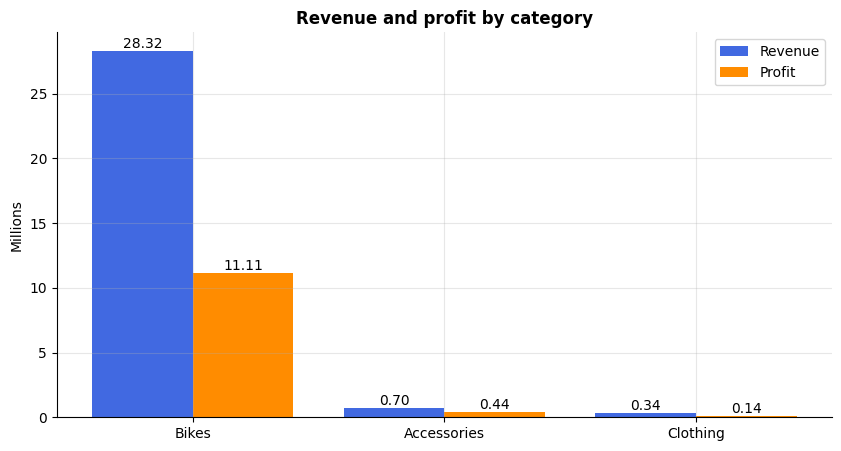

In [36]:
by_category = df.groupby("category")[["sales_amount", "profit"]].sum().sort_values("sales_amount", ascending=False)
by_category["margin_%"] = np.round(by_category["profit"] / by_category["sales_amount"] * 100, 1)
display(by_category)

x = np.arange(len(by_category))
bars1 = plt.bar(x - 0.2, by_category["sales_amount"] / 1e6, width=0.4, label="Revenue", color="royalblue")
bars2 = plt.bar(x + 0.2, by_category["profit"] / 1e6, width=0.4, label="Profit", color="darkorange")
plt.bar_label(bars1, fmt="%.2f")
plt.bar_label(bars2, fmt="%.2f")
plt.xticks(x, by_category.index)
plt.title("Revenue and profit by category")
plt.ylabel("Millions")
plt.legend()
plt.show()

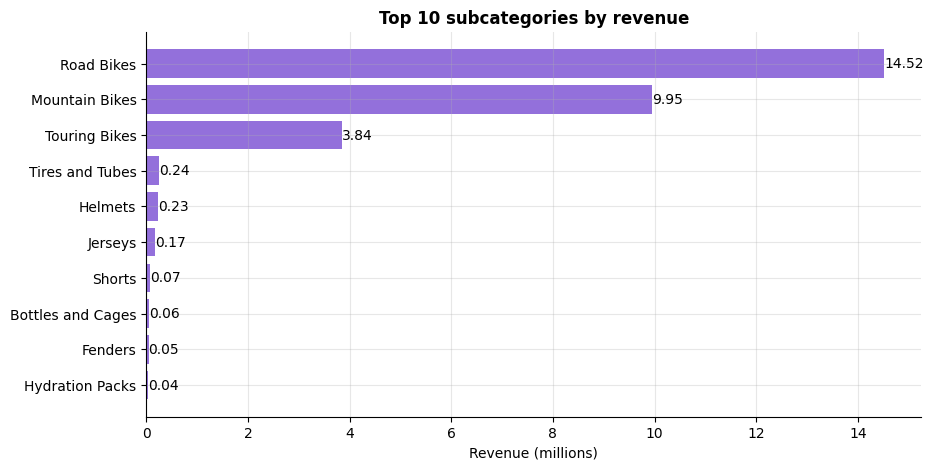

In [37]:
top_subcategories = df.groupby("subcategory")["sales_amount"].sum().nlargest(10).sort_values() / 1e6

bars = plt.barh(top_subcategories.index, top_subcategories.values, color="mediumpurple")
plt.bar_label(bars, fmt="%.2f")
plt.title("Top 10 subcategories by revenue")
plt.xlabel("Revenue (millions)")
plt.show()

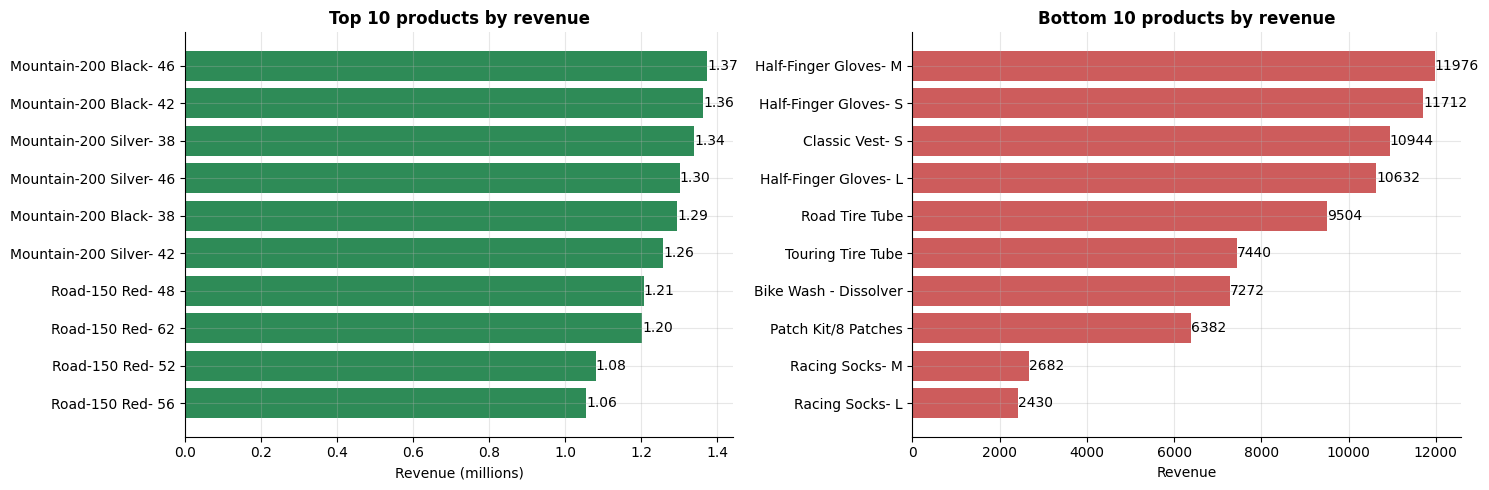

In [38]:
product_revenue = df.groupby("product_name")["sales_amount"].sum()
top10 = product_revenue.nlargest(10).sort_values()
bottom10 = product_revenue.nsmallest(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].barh(top10.index, top10.values / 1e6, color="seagreen")
axes[0].bar_label(bars, fmt="%.2f")
axes[0].set_title("Top 10 products by revenue")
axes[0].set_xlabel("Revenue (millions)")

bars = axes[1].barh(bottom10.index, bottom10.values, color="indianred")
axes[1].bar_label(bars)
axes[1].set_title("Bottom 10 products by revenue")
axes[1].set_xlabel("Revenue")

plt.tight_layout()
plt.show()

,Never sold,Sold
category,,
Accessories,7,22
Bikes,9,88
Clothing,15,20
Components,134,0


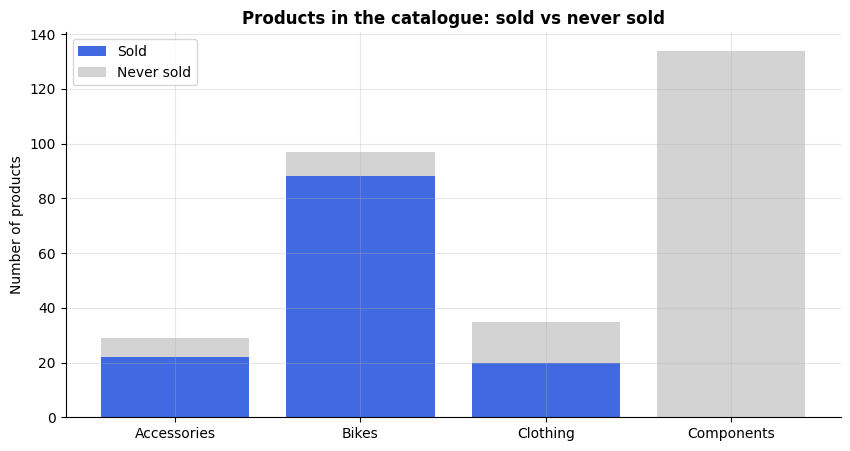

In [39]:
# How many products in each category were sold at least once?
sold = products["product_key"].isin(df["product_key"])
coverage = pd.crosstab(products["category"], sold)
coverage.columns = ["Never sold", "Sold"]
display(coverage)

plt.bar(coverage.index, coverage["Sold"], label="Sold", color="royalblue")
plt.bar(coverage.index, coverage["Never sold"], bottom=coverage["Sold"], label="Never sold", color="lightgray")
plt.title("Products in the catalogue: sold vs never sold")
plt.ylabel("Number of products")
plt.legend()
plt.show()

### 7.4 Countries

,revenue,customers,revenue_per_customer
country,,,
United States,9162327,7482,"1,225.00"
Australia,9060172,3591,"2,523.00"
United Kingdom,3391376,1913,"1,773.00"
Germany,2894066,1780,"1,626.00"
France,2643751,1810,"1,461.00"
Canada,1977738,1571,"1,259.00"
Unknown,226820,337,673.00


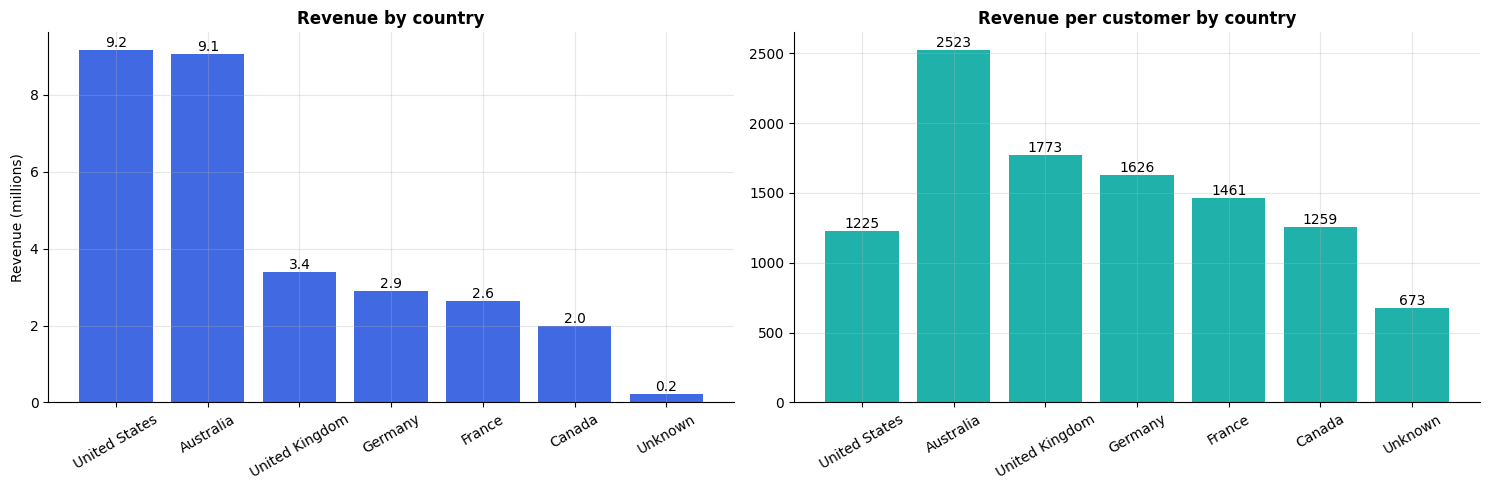

In [40]:
by_country = df.groupby("country").agg(revenue=("sales_amount", "sum"),
                                       customers=("customer_key", "nunique"))
by_country["revenue_per_customer"] = np.round(by_country["revenue"] / by_country["customers"])
by_country = by_country.sort_values("revenue", ascending=False)
display(by_country)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].bar(by_country.index, by_country["revenue"] / 1e6, color="royalblue")
axes[0].bar_label(bars, fmt="%.1f")
axes[0].set_title("Revenue by country")
axes[0].set_ylabel("Revenue (millions)")
axes[0].tick_params(axis="x", rotation=30)

bars = axes[1].bar(by_country.index, by_country["revenue_per_customer"], color="lightseagreen")
axes[1].bar_label(bars, fmt="%.0f")
axes[1].set_title("Revenue per customer by country")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### 7.5 Customers

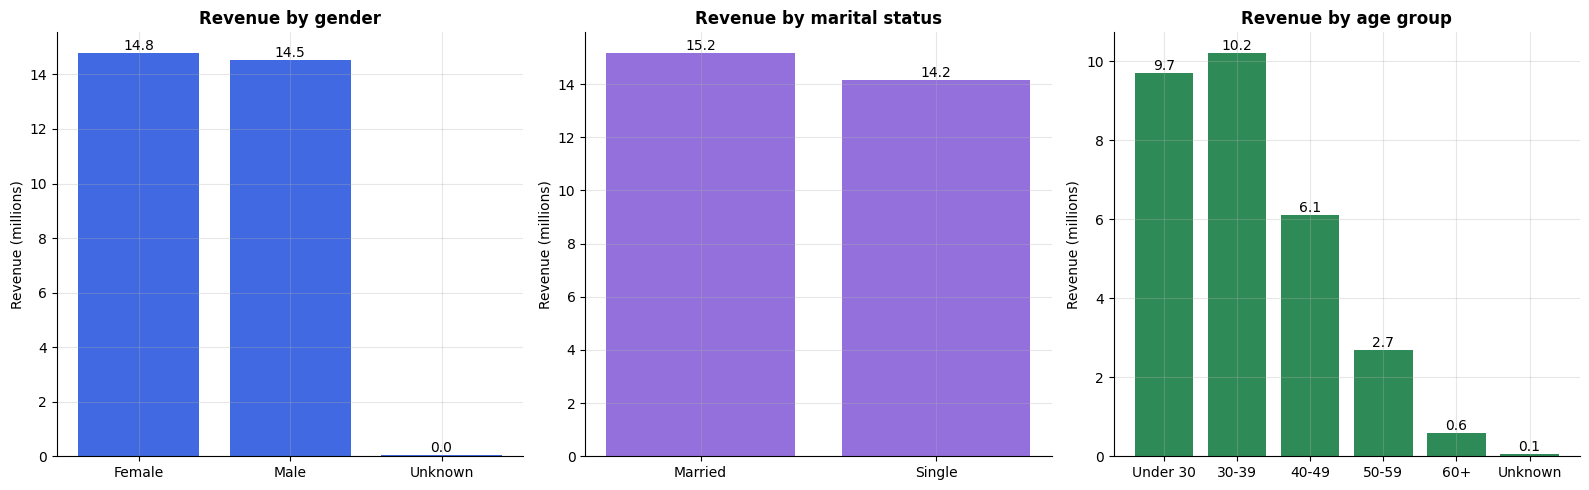

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column, color in zip(axes, ["gender", "marital_status", "age_group"], ["royalblue", "mediumpurple", "seagreen"]):
    revenue = df.groupby(column, observed=True)["sales_amount"].sum() / 1e6
    bars = ax.bar(revenue.index.astype(str), revenue.values, color=color)
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(f"Revenue by {column.replace('_', ' ')}")
    ax.set_ylabel("Revenue (millions)")

plt.tight_layout()
plt.show()

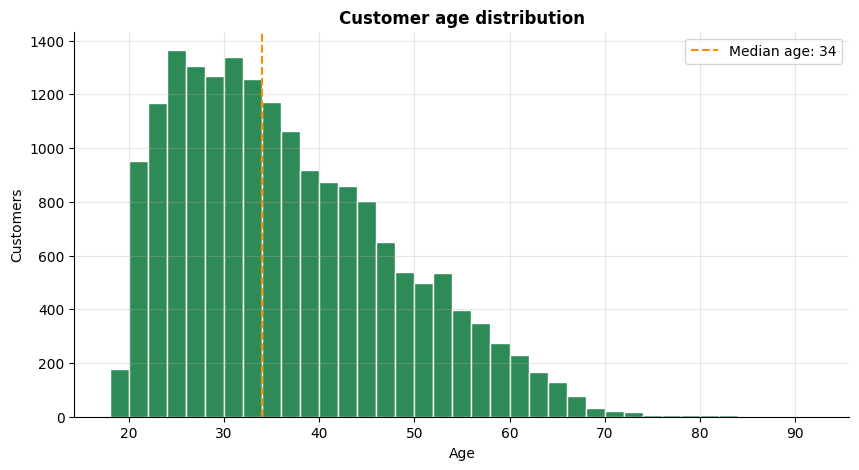

In [42]:
median_age = customers["age"].median()

plt.hist(customers["age"].dropna(), bins=np.arange(18, 94, 2), color="seagreen", edgecolor="white")
plt.axvline(median_age, color="darkorange", linestyle="--", label=f"Median age: {median_age:.0f}")
plt.title("Customer age distribution")
plt.xlabel("Age")
plt.ylabel("Customers")
plt.legend()
plt.show()

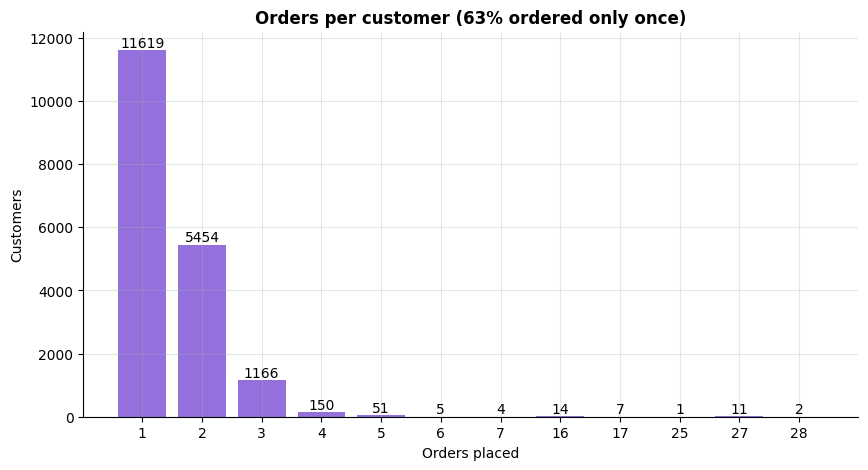

In [43]:
orders_per_customer = df.groupby("customer_key")["order_number"].nunique()
counts = orders_per_customer.value_counts().sort_index()
one_order_share = np.mean(orders_per_customer == 1) * 100

bars = plt.bar(counts.index.astype(str), counts.values, color="mediumpurple")
plt.bar_label(bars)
plt.title(f"Orders per customer ({one_order_share:.0f}% ordered only once)")
plt.xlabel("Orders placed")
plt.ylabel("Customers")
plt.show()

### 7.6 Orders and shipping

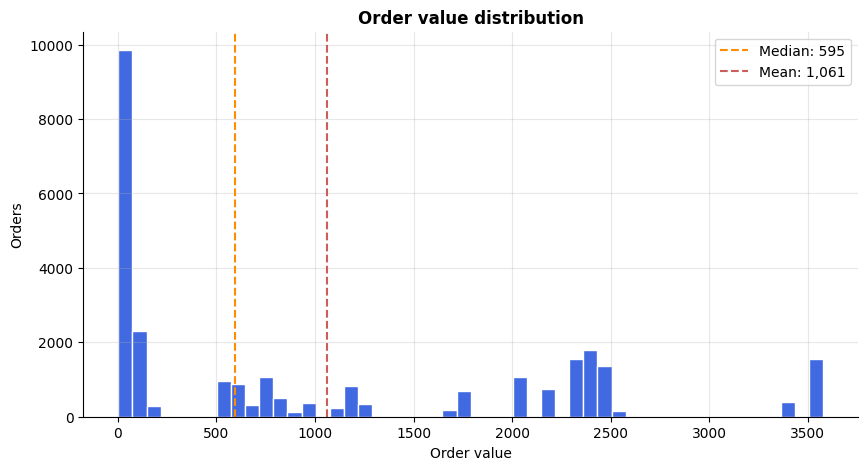

In [44]:
# Total value of each order
order_values = df.groupby("order_number")["sales_amount"].sum()

plt.hist(order_values, bins=50, color="royalblue", edgecolor="white")
plt.axvline(np.median(order_values), color="darkorange", linestyle="--", label=f"Median: {np.median(order_values):,.0f}")
plt.axvline(np.mean(order_values), color="indianred", linestyle="--", label=f"Mean: {np.mean(order_values):,.0f}")
plt.title("Order value distribution")
plt.xlabel("Order value")
plt.ylabel("Orders")
plt.legend()
plt.show()

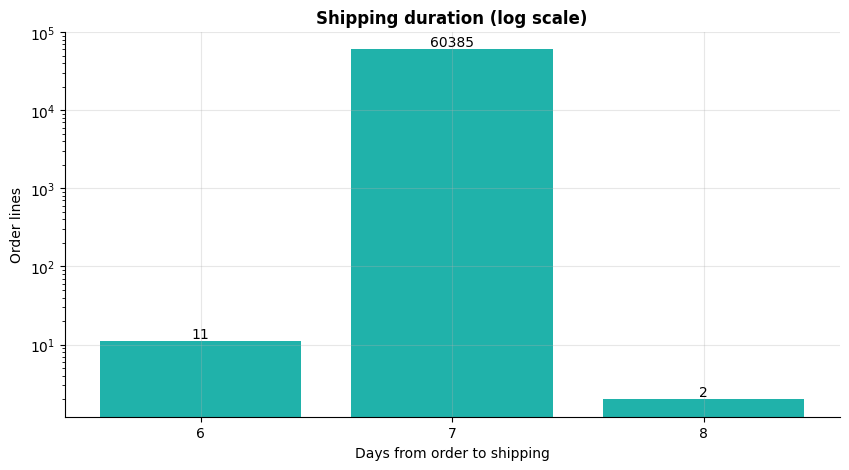

In [45]:
shipping_counts = df["shipping_duration"].value_counts().sort_index()

bars = plt.bar(shipping_counts.index.astype(str), shipping_counts.values, color="lightseagreen")
plt.bar_label(bars)
plt.yscale("log")   # log scale, because almost every order ships in 7 days
plt.title("Shipping duration (log scale)")
plt.xlabel("Days from order to shipping")
plt.ylabel("Order lines")
plt.show()

### 7.7 Key findings

- **Bikes drive the business:** about 96% of revenue and 95% of profit. Accessories and clothing sell many units but bring little revenue.
- **Overall profit margin is about 40%**, and accessories have the highest margin of the three categories that sold.
- **165 of 295 products (56%) never sold**, including all 134 Components products. So the Components fixes in cleaning only affect the catalogue, not any sales figures.
- **United States and Australia** each bring in about 31% of revenue, but Australian customers spend about twice as much per customer as US customers.
- **Orders jump from 2025** because accessories and clothing only start selling at the end of December 2024; before that, only bikes sold. This is why orders grow much faster than revenue.
- **63% of customers placed only one order**, and 92% placed one or two, which points to a retention opportunity.
- **Order values are split:** the median order is about 595, but many small accessory orders sit next to large bike orders.
- **Shipping** happens 7 days after the order in almost every case.

## 8. Export data

In [46]:
products.to_csv("/content/drive/MyDrive/products_clean.csv", index=False)
customers.to_csv("/content/drive/MyDrive/customers_clean.csv", index=False)
sales.to_csv("/content/drive/MyDrive/sales_clean.csv", index=False)
df.to_csv("/content/drive/MyDrive/sales_analysis.csv", index=False)